<a href="https://www.kaggle.com/code/ferntanyl/big-data?scriptVersionId=357979622" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

# Eksplorasi Mandiri Mahadata — Kerangka Analitik Big Data pada Apache Spark untuk Klasifikasi Aritmia EKG (MIT-BIH)

**Mata kuliah:** Mahadata (IF25-40402) · **Bentuk:** simulasi / perluasan (Panduan §4.1) · **Engine:** Apache Spark (PySpark, mode lokal)

## Artikel acuan
Shahzad, K., Javeed, A. M. D., Ahmad, S., Latif, M., & Saleem, K. (2026). Big data analytics and sentiment analysis for health misinformation detection: A systematic literature review of influencing factors, implementation challenges and a data-driven adoption framework. *Frontiers in Big Data, 9*, Article 1948398. https://doi.org/10.3389/fdata.2026.1948398

> **Catatan tentang tingkat replikasi.** Artikel acuan adalah *systematic literature review* (SLR): tidak memuat dataset, kode, maupun angka hasil eksperimen. Yang dioperasionalkan di notebook ini adalah **kerangka lima komponen (Gambar 5 artikel)** beserta temuan pendukungnya (§3.3–§3.4 artikel), pada domain berbeda (sinyal EKG, bukan teks media sosial). Jadi "perbandingan dengan artikel" bersifat **kualitatif** (apakah temuan artikel juga tampak pada data ini), bukan perbandingan angka.

## Pemetaan kerangka artikel → notebook

| # | Komponen kerangka artikel | Faktor / tantangan terkait | Implementasi di notebook | Bagian |
|---|---|---|---|---|
| 1 | Multi-source data acquisition layer | heterogenitas data, keterbatasan anotasi (§3.4.1, §5.1) | Sinyal EKG (CSV) dan anotasi beat (TXT) dibaca sebagai dua sumber ke Spark DataFrame + profiling kualitas | §1 |
| 2 | Intelligent data management system | *feature engineering*, kualitas data, seleksi fitur (§3.3.2, §5.2) | Normalisasi robust, segmentasi beat, 34 fitur (ritme + morfologi), pemetaan kelas AAMI, penyimpanan Parquet, seleksi fitur univariat | §2 |
| 3 | AI-driven analytical engine | deep learning / ML, sinyal tambahan, *real-time analytics* (§3.3.1, §3.3.3, §3.3.4, §5.3) | MLlib (LR, DT, RF, MLP); ablasi grup fitur sebagai analogi "sinyal tambahan"; Structured Streaming | §3–§4 |
| 4 | Human validation layer | verifikasi berpusat manusia (§3.3.5, §5.4) | Triase berbasis *confidence*: prediksi kurang yakin dirujuk ke ahli | §5 |
| 5 | Adaptive governance | etika, bias, skalabilitas, *drift* (§3.4.3–§3.4.5, §5.5) | Split antar-pasien, intra- vs antar-pasien, drift fitur, skalabilitas jumlah core, *provenance* | §6–§7 |

## Hipotesis yang diuji (boleh terbantahkan — laporkan apa adanya)
- **H1 (fusi fitur):** gabungan fitur ritme + morfologi lebih baik daripada salah satu grup saja — analog klaim artikel bahwa sinyal sentimen saja lemah dan perlu difusikan dengan fitur lain.
- **H2 (data > kompleksitas model):** skor intra-pasien lebih optimistik daripada antar-pasien; model lebih kompleks (MLP) tidak otomatis melampaui RF/LR (Diskusi artikel).
- **H3 (real-time vs skalabilitas):** latensi per *micro-batch* kecil dan jumlah core memengaruhi waktu pemrosesan secara tidak linear.
- **H4 (validasi manusia):** merujuk prediksi dengan *confidence* rendah menaikkan akurasi pada beat yang diterima, dengan biaya beban rujukan.
- **H5 (tata kelola):** performa dan sebaran fitur bergeser antar-pasien (*domain adaptation*, *concept drift*).

## Cara menjalankan (Kaggle)
1. *Add Data* → cari **mondejar/mitbih-database** (https://www.kaggle.com/datasets/mondejar/mitbih-database).
2. *Settings → Internet* aktif **hanya jika** PySpark perlu dipasang (sel §0 memasangnya otomatis bila belum ada).
3. *Run All*. Seed tetap `42`. Estimasi waktu 20–45 menit; atur `RUN_SCALABILITY = False` di §7 untuk melewati uji skalabilitas.
4. Semua tabel (`.csv`) dan grafik (`.png`) disimpan di `/kaggle/working/results/` untuk dimasukkan ke laporan.

> Kode ini belum pernah dijalankan pada dataset asli oleh pembuatnya; skema berkas dataset diperiksa otomatis di §1 dan bagian yang bergantung pada skema ditandai `# SKEMA`.

## §0. Konfigurasi, versi lingkungan, dan seed

In [1]:
#pip install --force-reinstall pyspark==4.0.1

In [2]:
import os, sys, json, time, glob, re, shutil, platform, subprocess, random, warnings
from datetime import datetime
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED); np.random.seed(SEED)

try:
    import pyspark
except ImportError:                       # Kaggle: aktifkan Internet bila perlu
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "pyspark==3.5.1"])
    import pyspark

from pyspark.sql import SparkSession, functions as F, types as T
from pyspark.ml import Pipeline
from pyspark.ml.feature import VectorAssembler, StandardScaler, UnivariateFeatureSelector
from pyspark.ml.classification import (LogisticRegression, DecisionTreeClassifier,
                                       RandomForestClassifier, MultilayerPerceptronClassifier)
from pyspark.ml.functions import vector_to_array

OUT_DIR = "/kaggle/working" if os.path.isdir("/kaggle/working") else "./outputs"
RES_DIR = os.path.join(OUT_DIR, "results")
os.makedirs(RES_DIR, exist_ok=True)

def java_version():
    try:
        r = subprocess.run(["java", "-version"], capture_output=True, text=True)
        return (r.stderr or r.stdout).splitlines()[0]
    except Exception as e:
        return f"Java tidak ditemukan: {e}"

ENV = {"python": platform.python_version(), "pyspark": pyspark.__version__, "numpy": np.__version__,
       "pandas": pd.__version__, "java": java_version(), "platform": platform.platform(),
       "cpu_count": os.cpu_count(), "started_at_utc": datetime.utcnow().isoformat() + "Z", "seed": SEED}
print(json.dumps(ENV, indent=2))

def build_spark(cores="*", mem=os.environ.get("SPARK_MEM", "8g"), app="mitbih-spark"):
    sp = (SparkSession.builder.master(f"local[{cores}]").appName(app)
          .config("spark.driver.memory", mem)
          .config("spark.sql.shuffle.partitions", "48")
          .config("spark.sql.execution.arrow.pyspark.enabled", "true")
          .config("spark.sql.session.timeZone", "UTC")
          .config("spark.ui.enabled", "false")
          .getOrCreate())
    sp.sparkContext.setLogLevel("ERROR")
    return sp

spark = build_spark()
print("Spark", spark.version, "| master:", spark.sparkContext.master,
      "| defaultParallelism:", spark.sparkContext.defaultParallelism)

# ---- utilitas umum ---------------------------------------------------------
RUNLOG = []
class stage:
    """Pencatat waktu eksekusi tiap tahap (untuk laporan)."""
    def __init__(self, name): self.name = name
    def __enter__(self): self.t0 = time.perf_counter(); return self
    def __exit__(self, *a):
        dt = time.perf_counter() - self.t0
        RUNLOG.append({"stage": self.name, "seconds": round(dt, 2)})
        print(f"[{self.name}] {dt:.1f} s")

def save_table(df, name):
    path = os.path.join(RES_DIR, name); df.to_csv(path, index=False); return path

def savefig(name):
    plt.tight_layout(); plt.savefig(os.path.join(RES_DIR, name), dpi=150); plt.show()

{
  "python": "3.13.15",
  "pyspark": "4.0.4",
  "numpy": "2.1.3",
  "pandas": "2.3.3",
  "java": "openjdk version \"21.0.12\" 2026-07-21",
  "platform": "Linux-6.18.48+-x86_64-with-glibc2.39",
  "cpu_count": 4,
  "started_at_utc": "2026-10-13T11:39:58.516802Z",
  "seed": 42
}


Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/13 11:40:02 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark 4.0.4 | master: local[*] | defaultParallelism: 4


## §1. Komponen 1 — Multi-source data acquisition layer
Artikel menekankan bahwa informasi tersebar di banyak sumber dengan struktur berbeda (heterogenitas) dan anotasi sering menjadi hambatan (§3.4.1). Di sini ada **dua sumber berbeda** per rekaman: (a) sinyal EKG berformat CSV, (b) anotasi beat berformat teks tabular. Keduanya dibaca terdistribusi oleh Spark.

**Konstanta domain** (diambil dari praktik standar MIT-BIH; periksa ulang sitasinya di laporan):
- Standar kelas AAMI EC57: **N** (normal), **S** (supraventrikular), **V** (ventrikular), **F** (fusi); kelas **Q** dibuang karena nyaris tidak ada setelah rekaman *paced* dikeluarkan.
- Rekaman *paced* (102, 104, 107, 217) dikeluarkan.
- Pembagian **antar-pasien** DS1 (latih) / DS2 (uji) mengikuti de Chazal et al. (2004): pasien di data uji tidak pernah muncul di data latih.

In [3]:
FS = 360.0                      # frekuensi sampling MIT-BIH (Hz)
PRE, POST = 90, 110             # jendela beat: 0,25 s sebelum dan 0,31 s sesudah puncak R
PACED = {"102", "104", "107", "217"}
DS1 = ["101","106","108","109","112","114","115","116","118","119","122","124",
       "201","203","205","207","208","209","215","220","223","230"]
DS2 = ["100","103","105","111","113","117","121","123","200","202","210","212",
       "213","214","219","221","222","228","231","232","233","234"]
USE = DS1 + DS2
CLASSES = ["N", "S", "V", "F"]
AAMI = {"N":"N","L":"N","R":"N","e":"N","j":"N",
        "A":"S","a":"S","J":"S","S":"S",
        "V":"V","E":"V",
        "F":"F",
        "/":"Q","f":"Q","Q":"Q"}
BEAT_SYMBOLS = set("NLRBAaJSVrFejnE/fQ?")   # kode anotasi WFDB yang merupakan beat

def find_data_dir():
    env = os.environ.get("MITBIH_DIR")
    if env and os.path.isfile(os.path.join(env, "100.csv")):
        return env
    hits = glob.glob("/kaggle/input/**/100.csv", recursive=True)
    if not hits:
        raise FileNotFoundError("100.csv tidak ditemukan. Tambahkan dataset mondejar/mitbih-database "
                                "lewat 'Add Data' (atau set env MITBIH_DIR).")
    return os.path.dirname(hits[0])

DATA_DIR = find_data_dir()
sig_files = sorted(glob.glob(os.path.join(DATA_DIR, "[0-9][0-9][0-9].csv")))
ann_files = sorted(glob.glob(os.path.join(DATA_DIR, "[0-9][0-9][0-9]annotations.txt")))
records = [os.path.basename(f)[:3] for f in sig_files]
print("DATA_DIR :", DATA_DIR)
print("berkas sinyal / anotasi:", len(sig_files), "/", len(ann_files))
missing = (set(DS1) | set(DS2) | PACED) - set(records)
if missing:
    print("PERINGATAN: rekaman tidak ditemukan:", sorted(missing))

# SKEMA: tampilkan sampel mentah agar skema dapat diverifikasi mata
print("\n--- 3 baris pertama 100.csv ---")
with open(os.path.join(DATA_DIR, "100.csv")) as fh:
    for _ in range(3): print(fh.readline().rstrip())
print("\n--- 6 baris pertama 100annotations.txt ---")
with open(os.path.join(DATA_DIR, "100annotations.txt")) as fh:
    for _ in range(6): print(fh.readline().rstrip())

DATA_DIR : /kaggle/input/datasets/mondejar/mitbih-database
berkas sinyal / anotasi: 48 / 48

--- 3 baris pertama 100.csv ---
'sample #','MLII','V5'
0,995,1011
1,995,1011

--- 6 baris pertama 100annotations.txt ---
      Time   Sample #  Type  Sub Chan  Num	Aux
    0:00.050       18     +    0    0    0	(N
    0:00.214       77     N    0    0    0
    0:01.028      370     N    0    0    0
    0:01.839      662     N    0    0    0
    0:02.628      946     N    0    0    0


In [4]:
# SKEMA: nama kolom lead berbeda antar rekaman (mis. MLII, V1, V2, V4, V5); pilih MLII bila ada.
def read_header(path):
    with open(path) as fh:
        line = fh.readline().strip()
    return [c.strip().strip("'\"").strip() for c in line.split(",")]

headers = {os.path.basename(f)[:3]: read_header(f) for f in sig_files}

def lead_position(h):
    sig = h[1:]
    return (sig.index("MLII") + 1) if "MLII" in sig else 1   # 1 -> kolom c1, 2 -> kolom c2

LEAD_COL = {r: lead_position(h) for r, h in headers.items()}
lead_tbl = pd.DataFrame({"record": list(headers), "header": [" | ".join(h) for h in headers.values()],
                         "kolom_dipakai": [LEAD_COL[r] for r in headers]})
print(lead_tbl.groupby("header").size().rename("jumlah_rekaman"))
print("Rekaman TANPA MLII (memakai kolom pertama):", [r for r, h in headers.items() if "MLII" not in h[1:]])

header
sample # | MLII | V1    40
sample # | MLII | V2     2
sample # | MLII | V4     1
sample # | MLII | V5     2
sample # | V5 | MLII     1
sample # | V5 | V2       2
Name: jumlah_rekaman, dtype: int64
Rekaman TANPA MLII (memakai kolom pertama): ['102', '104']


In [5]:
def load_sources(sp):
    """Membaca dua sumber (sinyal CSV, anotasi TXT) menjadi Spark DataFrame."""
    sig_paths = [f for f in sig_files if os.path.basename(f)[:3] in USE]
    ann_paths = [f for f in ann_files if os.path.basename(f)[:3] in USE]
    sig_schema = T.StructType([T.StructField("sample", T.LongType()),
                               T.StructField("c1", T.DoubleType()),
                               T.StructField("c2", T.DoubleType())])
    sig = (sp.read.csv(sig_paths, header=True, schema=sig_schema, mode="DROPMALFORMED")
             .withColumn("record", F.regexp_extract(F.input_file_name(), r"(\d{3})\.csv$", 1)))
    ann_raw = (sp.read.text(ann_paths)
                 .withColumn("record", F.regexp_extract(F.input_file_name(), r"(\d{3})annotations\.txt$", 1)))
    # SKEMA: baris data anotasi berbentuk "  0:00.214   77   N   0   0   0"
    pat = r"^\s*([\d:.]+)\s+(\d+)\s+(\S+)"
    ann = (ann_raw.where(F.col("value").rlike(r"^\s*\d+:\d+"))
           .select("record",
                   F.regexp_extract("value", pat, 2).cast("long").alias("sample"),
                   F.regexp_extract("value", pat, 3).alias("symbol")))
    return sig, ann

with stage("1. akuisisi + profiling"):
    sig, ann = load_sources(spark)
    sig_stats = (sig.groupBy("record")
                    .agg(F.count("*").alias("n_samples"), F.min("sample").alias("s_min"),
                         F.max("sample").alias("s_max"),
                         F.sum(F.col("c1").isNull().cast("int")).alias("null_c1"),
                         F.sum(F.col("c2").isNull().cast("int")).alias("null_c2"))
                    .orderBy("record").toPandas())
    ann_sym = ann.groupBy("symbol").count().orderBy(F.desc("count")).toPandas()

sig_stats["duration_min"] = sig_stats["n_samples"] / FS / 60
sig_stats["contiguous"] = (sig_stats["s_max"] - sig_stats["s_min"] + 1) == sig_stats["n_samples"]
print("rekaman terbaca:", len(sig_stats), "| total sampel:", f"{sig_stats.n_samples.sum():,}")
print(sig_stats[["n_samples", "duration_min", "null_c1", "null_c2"]].describe().round(2))
print("sampel kontigu pada semua rekaman:", bool(sig_stats.contiguous.all()))
print("\nSimbol anotasi (semua):"); print(ann_sym.to_string(index=False))
save_table(sig_stats, "01_profil_sinyal.csv"); save_table(ann_sym, "01_simbol_anotasi.csv")
assert ann_sym["count"].sum() > 50_000, "Parsing anotasi gagal: periksa regex pada load_sources()"

[1. akuisisi + profiling] 56.5 s
rekaman terbaca: 44 | total sampel: 28,600,000
       n_samples  duration_min  null_c1  null_c2
count       44.0         44.00     44.0     44.0
mean    650000.0         30.09      0.0      0.0
std          0.0          0.00      0.0      0.0
min     650000.0         30.09      0.0      0.0
25%     650000.0         30.09      0.0      0.0
50%     650000.0         30.09      0.0      0.0
75%     650000.0         30.09      0.0      0.0
max     650000.0         30.09      0.0      0.0
sampel kontigu pada semua rekaman: True

Simbol anotasi (semua):
symbol  count
     N  74546
     L   8075
     R   7259
     V   6903
     A   2546
     +   1173
     F    803
     ~    573
     !    472
     "    437
     j    229
     x    193
     a    150
     |    131
     E    106
     J     83
     e     16
     Q     15
     ]      6
     [      6
     S      2


**Untuk laporan (§B/§C):** jumlah rekaman, total sampel, durasi, simbol anotasi dominan, dan temuan kualitas (kolom lead berbeda, *null*, kontiguitas). Artikel menyebut data heterogen dan anotasi sebagai tantangan utama — catat apa yang benar-benar Anda temui di sini.

## §2. Komponen 2 — Intelligent data management system
Fungsi-fungsi artikel untuk komponen ini: pembersihan/normalisasi, *feature engineering*, seleksi fitur, representasi kontekstual. Padanannya pada EKG:

- **Normalisasi robust** per rekaman (median/MAD) — mengurangi perbedaan amplitudo antar pasien.
- **Segmentasi beat** di sekitar puncak R dari anotasi, lalu pemetaan simbol → kelas AAMI.
- **Dua grup fitur**: *ritme* (interval RR: konteks temporal) dan *morfologi* (bentuk gelombang). Dua grup ini menjadi analogi "sinyal tambahan vs konteks" pada artikel.
- Ekstraksi dijalankan **terdistribusi** per rekaman memakai `cogroup().applyInPandas()` Spark, hasilnya disimpan sebagai **Parquet** (penyimpanan kolumnar).

In [6]:
RHY = ["pre_rr", "post_rr", "avg_rr10", "pre_over_avg", "post_over_pre", "rr_diff"]
MOR = ["r_amp", "w_ptp", "w_std", "w_skew", "w_kurt", "w_energy", "qrs_w", "area_abs"] + \
      [f"wv{i:02d}" for i in range(20)]
FEATS = RHY + MOR
print(f"{len(RHY)} fitur ritme + {len(MOR)} fitur morfologi = {len(FEATS)} fitur")

def _moments(w):
    s = w.std()
    if s < 1e-12:
        return 0.0, 0.0
    z = (w - w.mean()) / s
    return float((z ** 3).mean()), float((z ** 4).mean() - 3.0)

def beat_features(x, pos, syms, fs=FS, pre=PRE, post=POST):
    """x: sinyal 1-D ternormalisasi; pos: indeks puncak R (terurut); syms: simbol anotasi tiap beat.
    Mengembalikan list dict fitur untuk beat berkelas AAMI N/S/V/F (beat pertama & terakhir dilewati)."""
    n = len(pos)
    rows = []
    if n < 3:
        return rows
    rr = np.diff(pos) / fs
    for i in range(1, n - 1):
        lab = AAMI.get(syms[i])
        if lab is None or lab == "Q":
            continue
        p = int(pos[i])
        if p - pre < 0 or p + post > len(x):
            continue
        w = np.asarray(x[p - pre: p + post], dtype=float)
        w = w - w[:10].mean()                                   # koreksi baseline sederhana
        seg = w[pre - 10: pre + 11]
        k = int(np.argmax(np.abs(seg)))
        r_amp = float(seg[k])
        pre_rr, post_rr = float(rr[i - 1]), float(rr[i])
        avg10 = float(rr[max(0, i - 10): i].mean())
        sk, ku = _moments(w)
        half = 0.5 * abs(r_amp)
        core = w[pre - 40: pre + 40]
        qrs_w = float((np.abs(core) > half).sum()) / fs if half > 0 else 0.0
        row = {"sample": p, "symbol": str(syms[i]), "label": lab, "qc_offset": k - 10,
               "pre_rr": pre_rr, "post_rr": post_rr, "avg_rr10": avg10,
               "pre_over_avg": pre_rr / avg10 if avg10 > 0 else 1.0,
               "post_over_pre": post_rr / pre_rr if pre_rr > 0 else 1.0,
               "rr_diff": post_rr - pre_rr,
               "r_amp": r_amp, "w_ptp": float(w.max() - w.min()), "w_std": float(w.std()),
               "w_skew": sk, "w_kurt": ku, "w_energy": float((w ** 2).mean()),
               "qrs_w": qrs_w, "area_abs": float(np.abs(w).sum() / fs)}
        for j, v in enumerate(w[::10][:20]):
            row[f"wv{j:02d}"] = float(v)
        rows.append(row)
    return rows

OUT_SCHEMA = T.StructType(
    [T.StructField("record", T.StringType()), T.StructField("sample", T.LongType()),
     T.StructField("symbol", T.StringType()), T.StructField("label", T.StringType()),
     T.StructField("qc_offset", T.LongType())] + [T.StructField(c, T.DoubleType()) for c in FEATS])
OUT_COLS = [f.name for f in OUT_SCHEMA.fields]

def extract_beats(key, sig_pdf, ann_pdf):
    """Dijalankan Spark sekali per rekaman (cogroup sinyal x anotasi)."""
    rec = key[0]
    empty = pd.DataFrame({c: [] for c in OUT_COLS})
    if len(sig_pdf) == 0 or len(ann_pdf) == 0:
        return empty
    sig_pdf = sig_pdf.sort_values("sample")
    x = np.nan_to_num(sig_pdf["c%d" % LEAD_COL.get(rec, 1)].to_numpy(dtype=float))
    med = np.median(x); mad = np.median(np.abs(x - med)) * 1.4826
    x = (x - med) / (mad if mad > 1e-9 else 1.0)                 # normalisasi robust per rekaman
    smp = sig_pdf["sample"].to_numpy()
    ann = ann_pdf[ann_pdf["symbol"].isin(BEAT_SYMBOLS)].sort_values("sample")
    pos = np.searchsorted(smp, ann["sample"].to_numpy())
    keep = pos < len(smp)
    rows = beat_features(x, pos[keep], ann["symbol"].to_numpy()[keep])
    if not rows:
        return empty
    out = pd.DataFrame(rows)
    out["record"] = rec
    out["sample"] = out["sample"].astype("int64")
    out["qc_offset"] = out["qc_offset"].astype("int64")
    for c in FEATS:
        out[c] = out[c].astype("float64")
    return out[OUT_COLS]

def build_features(sig, ann):
    ann_b = ann.where(F.col("symbol").isin(sorted(BEAT_SYMBOLS)))
    feat = (sig.select("record", "sample", "c1", "c2").groupBy("record")
              .cogroup(ann_b.groupBy("record")).applyInPandas(extract_beats, schema=OUT_SCHEMA))
    lab_map = F.create_map([F.lit(v) for i, c in enumerate(CLASSES) for v in (c, float(i))])
    return (feat.withColumn("split", F.when(F.col("record").isin(DS1), "DS1").otherwise("DS2"))
                .withColumn("y", lab_map[F.col("label")]))

6 fitur ritme + 28 fitur morfologi = 34 fitur


[2. ekstraksi fitur terdistribusi -> Parquet] 83.5 s
total beat berfitur: 100,630 | partisi Parquet: 6

Distribusi kelas per split:
label      N     S     V    F  total
split                               
DS1    45824   943  3788  414  50969
DS2    44218  1836  3219  388  49661

QC keselarasan anotasi-sinyal:
 frac_puncak_selaras_3sampel  rerata_abs_offset_sampel
                      0.9667                    1.0177
jumlah nilai null pada fitur: 0


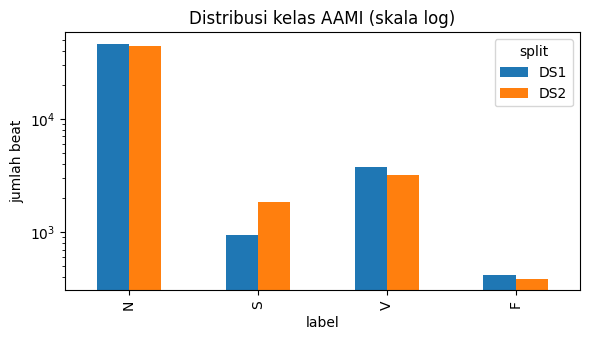

In [7]:
feat_path = os.path.join(OUT_DIR, "beat_features.parquet")
with stage("2. ekstraksi fitur terdistribusi -> Parquet"):
    build_features(sig, ann).write.mode("overwrite").parquet(feat_path)
    feat = spark.read.parquet(feat_path).cache()
    n_beats = feat.count()
print("total beat berfitur:", f"{n_beats:,}", "| partisi Parquet:", len(glob.glob(feat_path + "/*.parquet")))

dist = (feat.groupBy("split", "label").count().toPandas()
            .pivot(index="split", columns="label", values="count").reindex(columns=CLASSES).fillna(0).astype(int))
dist["total"] = dist.sum(axis=1)
print("\nDistribusi kelas per split:"); print(dist)
save_table(dist.reset_index(), "02_distribusi_kelas.csv")

qc = feat.agg(F.mean((F.abs("qc_offset") <= 3).cast("double")).alias("frac_puncak_selaras_3sampel"),
              F.mean(F.abs("qc_offset").cast("double")).alias("rerata_abs_offset_sampel")).toPandas()
nul = feat.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in FEATS]).toPandas().sum(axis=1).iloc[0]
print("\nQC keselarasan anotasi-sinyal:"); print(qc.round(4).to_string(index=False))
print("jumlah nilai null pada fitur:", int(nul))

ax = dist[CLASSES].T.plot(kind="bar", logy=True, figsize=(6, 3.5))
ax.set_title("Distribusi kelas AAMI (skala log)"); ax.set_ylabel("jumlah beat"); savefig("02_distribusi_kelas.png")

In [8]:
train = feat.where(F.col("split") == "DS1").cache()
test = feat.where(F.col("split") == "DS2").cache()

def class_weights(df):
    rows = df.groupBy("y").count().collect()
    tot = sum(r["count"] for r in rows); k = len(rows)
    return {float(r["y"]): tot / (k * r["count"]) for r in rows}

def add_weights(df, wmap):
    expr = F.create_map([F.lit(v) for kv in wmap.items() for v in kv])
    return df.withColumn("w", expr[F.col("y")])

wmap = class_weights(train)
print("bobot kelas (N,S,V,F) dari DS1:", {CLASSES[int(k)]: round(v, 2) for k, v in sorted(wmap.items())})
train_w = add_weights(train, wmap).cache(); train_w.count()

# seleksi fitur otomatis (analog 'automatic feature selection' pada Tabel 5 artikel)

asm = VectorAssembler(
    inputCols=FEATS,
    outputCol="fr",
    handleInvalid="keep"
)

selector = (
    UnivariateFeatureSelector(
        featuresCol="fr",
        outputCol="fs",
        labelCol="y",
        selectionMode="numTopFeatures"
    )
    .setFeatureType("continuous")
    .setLabelType("categorical")
    .setSelectionThreshold(20)
)

sel_model = selector.fit(asm.transform(train))

print(
    "20 fitur terpilih (ANOVA F):",
    [FEATS[i] for i in sorted(sel_model.selectedFeatures)]
)


bobot kelas (N,S,V,F) dari DS1: {'N': 0.28, 'S': 13.51, 'V': 3.36, 'F': 30.78}


20 fitur terpilih (ANOVA F): ['pre_rr', 'post_rr', 'avg_rr10', 'pre_over_avg', 'post_over_pre', 'rr_diff', 'r_amp', 'w_std', 'w_skew', 'w_kurt', 'w_energy', 'qrs_w', 'area_abs', 'wv00', 'wv01', 'wv02', 'wv03', 'wv04', 'wv05', 'wv06']


**Untuk laporan (§B langkah praproses; §C kualitas data):** distribusi kelas (ketimpangan), proporsi puncak R yang selaras dengan anotasi, fitur terpilih. Hubungkan dengan artikel: kualitas dan representativitas data sering lebih menentukan daripada kompleksitas model (Diskusi §4 artikel).

## §3. Komponen 3 — AI-driven analytical engine
Spark MLlib menjalankan beberapa algoritma, dengan perlakuan ketimpangan kelas (pada artikel: *Balanced Random Forest* untuk data tak seimbang, Kabir 2022 dalam Tabel 5) dan evaluasi berbasis *confusion matrix*. Metrik utama **macro-F1** (akurasi menyesatkan karena kelas N dominan).

In [9]:
def metrics_from(y, p, k=len(CLASSES)):
    y = np.asarray(y).astype(int); p = np.asarray(p).astype(int)
    cm = np.zeros((k, k), dtype=int); np.add.at(cm, (y, p), 1)
    tp = np.diag(cm).astype(float); sup = cm.sum(1)
    prec = tp / np.maximum(cm.sum(0), 1); rec = tp / np.maximum(sup, 1)
    f1 = np.where(prec + rec > 0, 2 * prec * rec / np.maximum(prec + rec, 1e-12), 0.0)
    present = sup > 0
    return {"acc": tp.sum() / max(cm.sum(), 1), "macro_f1": f1[present].mean() if present.any() else np.nan,
            "f1": f1, "rec": np.where(present, rec, np.nan), "prec": prec, "support": sup, "cm": cm}

def build_pipeline(kind, cols, nt=100, md=12, n_sel=20, hidden=(64, 32)):
    stages = [VectorAssembler(inputCols=cols, outputCol="f_raw", handleInvalid="keep")]
    fcol = "f_raw"
    if kind in ("LR", "MLP"):
        stages.append(StandardScaler(inputCol=fcol, outputCol="f_std", withMean=True, withStd=True)); fcol = "f_std"
    if kind == "RF_FS":
        # API UnivariateFeatureSelector: tipe fitur/label dan threshold diatur via setter.
        selector = UnivariateFeatureSelector(
            featuresCol=fcol,
            outputCol="f_sel",
            labelCol="y",
            selectionMode="numTopFeatures"
        )
        selector = (
            selector
            .setFeatureType("continuous")
            .setLabelType("categorical")
            .setSelectionThreshold(n_sel)
        )
        stages.append(selector)
        fcol = "f_sel"
    if kind == "LR":
        clf = LogisticRegression(featuresCol=fcol, labelCol="y", weightCol="w", family="multinomial",
                                 maxIter=200, regParam=0.01)
    elif kind == "DT":
        clf = DecisionTreeClassifier(featuresCol=fcol, labelCol="y", weightCol="w", maxDepth=md, seed=SEED)
    elif kind in ("RF", "RF_FS"):
        clf = RandomForestClassifier(featuresCol=fcol, labelCol="y", weightCol="w", numTrees=nt, maxDepth=md, seed=SEED)
    elif kind == "RF_NOW":                       # tanpa bobot kelas (pembanding)
        clf = RandomForestClassifier(featuresCol=fcol, labelCol="y", numTrees=nt, maxDepth=md, seed=SEED)
    elif kind == "MLP":
        clf = MultilayerPerceptronClassifier(featuresCol=fcol, labelCol="y", maxIter=150, blockSize=128, seed=SEED,
                                             layers=[len(cols), *hidden, len(CLASSES)])
    else:
        raise ValueError(kind)
    stages.append(clf)
    return Pipeline(stages=stages)

def fit_eval(kind, cols, train_df, test_df, **kw):
    t0 = time.perf_counter(); model = build_pipeline(kind, cols, **kw).fit(train_df); t_fit = time.perf_counter() - t0
    t1 = time.perf_counter(); pdf = model.transform(test_df).select("y", "prediction").toPandas(); t_pred = time.perf_counter() - t1
    return model, metrics_from(pdf["y"], pdf["prediction"]), t_fit, t_pred

def result_row(name, m, t_fit, t_pred, **extra):
    r = {"model": name, "accuracy": m["acc"], "macro_f1": m["macro_f1"]}
    r.update({f"recall_{c}": m["rec"][i] for i, c in enumerate(CLASSES)})
    r.update({f"f1_{c}": m["f1"][i] for i, c in enumerate(CLASSES)})
    r.update({"fit_s": t_fit, "predict_s": t_pred}); r.update(extra)
    return r

### §3a. Penyetelan hiperparameter dengan validasi silang **antar-pasien**
Validasi silang acak akan membocorkan beat pasien yang sama ke lipatan uji. Karena itu lipatan dibentuk **per pasien** (3 lipatan dari 22 rekaman DS1).

In [10]:
ds1_sorted = sorted(DS1)
fold_map = {r: i % 3 for i, r in enumerate(ds1_sorted)}
fold_expr = F.create_map([F.lit(v) for kv in fold_map.items() for v in kv])
tr_cv = train_w.withColumn("fold", fold_expr[F.col("record")].cast("int")).cache(); tr_cv.count()

grid = [(nt, md) for nt in (60, 120) for md in (8, 12)]
cv_rows = []
with stage("3a. CV antar-pasien (RF, 4 kombinasi x 3 lipatan)"):
    for nt, md in grid:
        scores = []
        for f in range(3):
            tr_f, va_f = tr_cv.where(F.col("fold") != f), tr_cv.where(F.col("fold") == f)
            _, m, _, _ = fit_eval("RF", FEATS, tr_f, va_f, nt=nt, md=md)
            scores.append(m["macro_f1"])
        cv_rows.append({"numTrees": nt, "maxDepth": md, "macro_f1_mean": float(np.nanmean(scores)),
                        "macro_f1_std": float(np.nanstd(scores)), **{f"fold{i}": s for i, s in enumerate(scores)}})
cv_df = pd.DataFrame(cv_rows).sort_values("macro_f1_mean", ascending=False)
print(cv_df.round(4).to_string(index=False)); save_table(cv_df, "03a_cv_antar_pasien.csv")
BEST = {"nt": int(cv_df.iloc[0]["numTrees"]), "md": int(cv_df.iloc[0]["maxDepth"])}
print("hiperparameter terpilih:", BEST)

[3a. CV antar-pasien (RF, 4 kombinasi x 3 lipatan)] 144.6 s
 numTrees  maxDepth  macro_f1_mean  macro_f1_std  fold0  fold1  fold2
      120        12         0.4560        0.0224 0.4877 0.4395 0.4408
       60         8         0.4550        0.0214 0.4839 0.4327 0.4483
      120         8         0.4539        0.0227 0.4849 0.4313 0.4453
       60        12         0.4537        0.0186 0.4801 0.4401 0.4409
hiperparameter terpilih: {'nt': 120, 'md': 12}


### §3b. Ablasi grup fitur (uji H1)
Analogi langsung pada klaim artikel: sinyal tunggal (di artikel: sentimen) punya daya pembeda terbatas dan perlu difusikan dengan fitur lain (Alonso et al., 2021 dalam Tabel 5 artikel). Di sini: ritme saja vs morfologi saja vs fusi.

[3b. ablasi grup fitur] 101.6 s
                    model  accuracy  macro_f1  recall_N  recall_S  recall_V  recall_F
           Ritme saja (6)    0.8424    0.4429    0.8852    0.1095    0.7269    0.3866
      Morfologi saja (28)    0.8948    0.4639    0.9414    0.0452    0.8484    0.0000
Fusi ritme+morfologi (34)    0.9383    0.5134    0.9825    0.0937    0.9251    0.0000


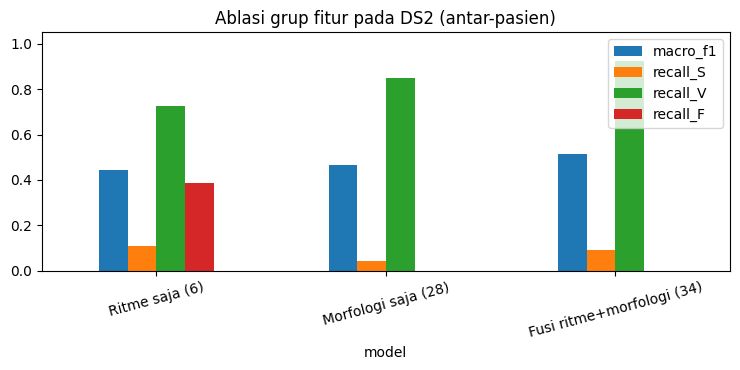

In [11]:
abl_rows, abl_models = [], {}
with stage("3b. ablasi grup fitur"):
    for name, cols in {"Ritme saja (6)": RHY, "Morfologi saja (28)": MOR, "Fusi ritme+morfologi (34)": FEATS}.items():
        model, m, tf, tp = fit_eval("RF", cols, train_w, test, nt=BEST["nt"], md=BEST["md"])
        abl_models[name] = model; abl_rows.append(result_row(name, m, tf, tp, n_features=len(cols)))
abl = pd.DataFrame(abl_rows)
print(abl[["model", "accuracy", "macro_f1", "recall_N", "recall_S", "recall_V", "recall_F"]].round(4).to_string(index=False))
save_table(abl, "03b_ablasi_fitur.csv")
final_model = abl_models["Fusi ritme+morfologi (34)"]

ax = abl.set_index("model")[["macro_f1", "recall_S", "recall_V", "recall_F"]].plot(kind="bar", figsize=(7.5, 3.8), rot=15)
ax.set_title("Ablasi grup fitur pada DS2 (antar-pasien)"); ax.set_ylim(0, 1.05); savefig("03b_ablasi_fitur.png")

### §3c. Perbandingan model (uji sebagian H2)
LR, DT, RF (berbobot kelas), RF tanpa bobot, RF + seleksi fitur, dan MLP (representasi sederhana dari jaringan saraf; MLlib tidak mendukung bobot kelas pada MLP, sehingga dilatih pada data DS1 yang mayoritasnya di-*undersample*).

ukuran DS1 setelah undersample (untuk MLP): 9268


[3c. perbandingan model] 106.1 s
                           model  accuracy  macro_f1  recall_S  recall_V  recall_F   fit_s
     Regresi Logistik (berbobot)    0.8177    0.5251    0.4069    0.8633    0.4459  6.1007
Random Forest + seleksi 20 fitur    0.9327    0.5172    0.1302    0.9174    0.0000 29.8481
     Random Forest (tanpa bobot)    0.9488    0.5151    0.0937    0.8978    0.0000 25.1258
        Random Forest (berbobot)    0.9383    0.5134    0.0937    0.9251    0.0000 26.0707
        Decision Tree (berbobot)    0.8630    0.4880    0.2908    0.8291    0.0077  2.3971
    MLP 34-64-32-4 (undersample)    0.8108    0.4531    0.2576    0.9332    0.1031  9.2868


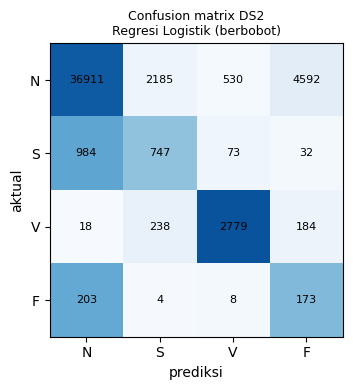

In [12]:
cnt = {float(r["y"]): r["count"] for r in train.groupBy("y").count().collect()}
CAP = 4000
train_bal = train.sampleBy("y", fractions={k: min(1.0, CAP / v) for k, v in cnt.items()}, seed=SEED).cache()
print("ukuran DS1 setelah undersample (untuk MLP):", train_bal.count())

cmp_rows, cmp_models = [], {}
specs = [("Regresi Logistik (berbobot)", "LR", train_w, {}),
         ("Decision Tree (berbobot)", "DT", train_w, {"md": BEST["md"]}),
         ("Random Forest (berbobot)", "RF", train_w, {"nt": BEST["nt"], "md": BEST["md"]}),
         ("Random Forest (tanpa bobot)", "RF_NOW", train, {"nt": BEST["nt"], "md": BEST["md"]}),
         ("Random Forest + seleksi 20 fitur", "RF_FS", train_w, {"nt": BEST["nt"], "md": BEST["md"]}),
         ("MLP 34-64-32-4 (undersample)", "MLP", train_bal, {})]
with stage("3c. perbandingan model"):
    for name, kind, tr_df, kw in specs:
        model, m, tf, tp = fit_eval(kind, FEATS, tr_df, test, **kw)
        cmp_models[name] = (model, m); cmp_rows.append(result_row(name, m, tf, tp))
cmp_df = pd.DataFrame(cmp_rows).sort_values("macro_f1", ascending=False)
print(cmp_df[["model", "accuracy", "macro_f1", "recall_S", "recall_V", "recall_F", "fit_s"]].round(4).to_string(index=False))
save_table(cmp_df, "03c_perbandingan_model.csv")

best_name = cmp_df.iloc[0]["model"]; cm = cmp_models[best_name][1]["cm"]
fig, ax = plt.subplots(figsize=(4.6, 4))
im = ax.imshow(cm / np.maximum(cm.sum(1, keepdims=True), 1), cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(4)); ax.set_xticklabels(CLASSES); ax.set_yticks(range(4)); ax.set_yticklabels(CLASSES)
for i in range(4):
    for j in range(4):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8, color="black")
ax.set_xlabel("prediksi"); ax.set_ylabel("aktual"); ax.set_title(f"Confusion matrix DS2\n{best_name}", fontsize=9)
savefig("03c_confusion_matrix.png")

### §3d. Intra-pasien vs antar-pasien (uji H2 dan H5)
Model yang sama (RF berbobot, hiperparameter terpilih) dinilai dengan dua skema: **acak per beat** (beat pasien yang sama bisa ada di latih dan uji) dan **antar-pasien** (DS1→DS2). Selisihnya menunjukkan seberapa optimistik evaluasi yang tidak mempertimbangkan representativitas data — tema "sampling bias" dan "domain adaptation" pada artikel.

In [13]:
tr_i, te_i = feat.randomSplit([0.7, 0.3], seed=SEED)
tr_iw = add_weights(tr_i, class_weights(tr_i))
with stage("3d. intra vs antar pasien"):
    _, m_intra, tf1, tp1 = fit_eval("RF", FEATS, tr_iw, te_i, nt=BEST["nt"], md=BEST["md"])
m_inter = cmp_models["Random Forest (berbobot)"][1]
ii = pd.DataFrame([result_row("Intra-pasien (acak 70/30)", m_intra, tf1, tp1),
                   result_row("Antar-pasien (DS1->DS2)", m_inter, np.nan, np.nan)])
print(ii[["model", "accuracy", "macro_f1", "recall_S", "recall_V", "recall_F"]].round(4).to_string(index=False))
print("selisih macro-F1 (intra - antar):", round(m_intra["macro_f1"] - m_inter["macro_f1"], 4))
save_table(ii, "03d_intra_vs_antar_pasien.csv")

[3d. intra vs antar pasien] 40.5 s
                    model  accuracy  macro_f1  recall_S  recall_V  recall_F
Intra-pasien (acak 70/30)    0.9838    0.8683    0.9037    0.9713    0.8468
  Antar-pasien (DS1->DS2)    0.9383    0.5134    0.0937    0.9251    0.0000
selisih macro-F1 (intra - antar): 0.3549


'/kaggle/working/results/03d_intra_vs_antar_pasien.csv'

**Untuk laporan (§C):** tabel §3a–§3d. Tulis apakah H1 dan H2 terdukung, dan jelaskan penyebabnya (mis. kelas minoritas S/F, variasi morfologi antar-pasien). Bila hasil menyelisihi artikel, itu temuan yang sah selama dijelaskan jujur (Panduan §6).

## §4. Real-time analytics (bagian dari Komponen 3) — Spark Structured Streaming
Artikel memandang kemampuan *real-time* sebagai persyaratan operasional yang harus diimbangi skalabilitas, bukan indikator keunggulan (Diskusi §4). Simulasi: data uji DS2 ditulis sebagai beberapa berkas Parquet, lalu dialirkan **satu berkas per *micro-batch*** ke model terlatih; latensi dan *throughput* dicatat. Bandingkan dengan kebutuhan klinis: sekitar satu beat per ~0,8 detik per pasien.

In [14]:
stream_cols = ["record", "sample", "y", "label"] + FEATS
stream_dir = os.path.join(OUT_DIR, "stream_in"); ckpt = os.path.join(OUT_DIR, "stream_ckpt")
for d in (stream_dir, ckpt): shutil.rmtree(d, ignore_errors=True)
test.select(*stream_cols).repartition(8).write.parquet(stream_dir)
sdf = spark.readStream.schema(test.select(*stream_cols).schema).option("maxFilesPerTrigger", 1).parquet(stream_dir)

stream_log = []
def process_batch(bdf, bid):
    t0 = time.perf_counter()
    out = final_model.transform(bdf).select("y", "prediction").toPandas()
    dt = time.perf_counter() - t0
    stream_log.append({"batch": int(bid), "rows": len(out), "seconds": dt,
                       "ms_per_beat": 1000 * dt / max(len(out), 1), "beats_per_s": len(out) / dt if dt > 0 else np.nan})

with stage("4. structured streaming (micro-batch)"):
    writer = sdf.writeStream.foreachBatch(process_batch).option("checkpointLocation", ckpt)
    try:
        q = writer.trigger(availableNow=True).start()
    except Exception:
        q = writer.trigger(once=True).start()
    q.awaitTermination()

stream_df = pd.DataFrame(stream_log)
print(stream_df.round(4).to_string(index=False))
steady = stream_df.iloc[1:] if len(stream_df) > 1 else stream_df     # batch pertama memuat warm-up JVM
print(f"\nmedian latensi per micro-batch (tanpa batch pertama): {steady.seconds.median():.2f} s "
      f"untuk ~{int(steady.rows.median())} beat; median {steady.ms_per_beat.median():.3f} ms/beat; "
      f"throughput {steady.beats_per_s.median():,.0f} beat/s")
save_table(stream_df, "04_streaming_microbatch.csv")

[4. structured streaming (micro-batch)] 10.7 s
 batch  rows  seconds  ms_per_beat  beats_per_s
     0  6208   1.5309       0.2466    4055.1280
     1  6207   1.0912       0.1758    5688.2660
     2  6208   1.1027       0.1776    5629.8985
     3  6208   1.1832       0.1906    5246.8936
     4  6207   1.0842       0.1747    5724.9634
     5  6207   0.8976       0.1446    6914.7529
     6  6208   0.9536       0.1536    6510.0230
     7  6208   0.9149       0.1474    6785.2859

median latensi per micro-batch (tanpa batch pertama): 1.08 s untuk ~6208 beat; median 0.175 ms/beat; throughput 5,725 beat/s


'/kaggle/working/results/04_streaming_microbatch.csv'

## §5. Komponen 4 — Human validation layer (uji H4)
Artikel: keluaran otomatis perlu ditinjau ahli pada kasus ambigu (§3.3.5, §5.4), tanpa mengasumsikan bahwa validasi manusia otomatis menjamin akurasi. Simulasi: beat dengan probabilitas tertinggi < ambang τ **dirujuk ke ahli**; sisanya diterima otomatis. Dilaporkan akurasi pada beat yang diterima, cakupan (otomatis), dan berapa persen kesalahan model yang tertangkap rujukan.

 tau  cakupan_otomatis  dirujuk  akurasi_diterima  macroF1_diterima  kesalahan_tertangkap  beat_V_dirujuk
 0.0            1.0000   0.0000            0.9383            0.5134                0.0000          0.0000
 0.4            0.9984   0.0016            0.9389            0.5134                0.0117          0.0043
 0.5            0.9834   0.0166            0.9458            0.5144                0.1367          0.0488
 0.6            0.9524   0.0476            0.9569            0.5174                0.3351          0.1177
 0.7            0.9133   0.0867            0.9647            0.5196                0.4770          0.1901
 0.8            0.7915   0.2085            0.9796            0.5207                0.7387          0.2759
 0.9            0.6073   0.3927            0.9942            0.5144                0.9432          0.4321


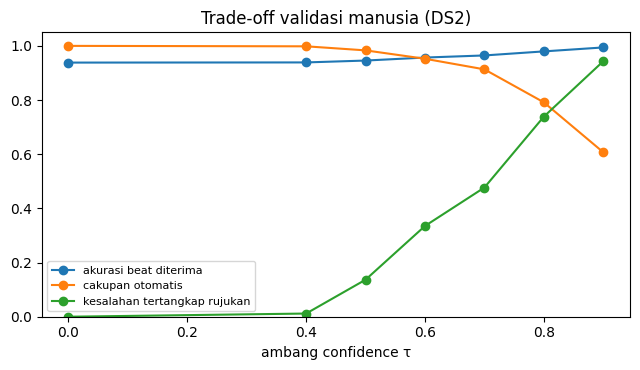

In [15]:
pred_test = (final_model.transform(test)
             .select("record", "y", "prediction", F.array_max(vector_to_array("probability")).alias("maxp"))
             .toPandas())
y, p, mp = pred_test["y"].to_numpy(), pred_test["prediction"].to_numpy(), pred_test["maxp"].to_numpy()
err = y != p
tri_rows = []
for tau in [0.0, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    acc_mask = mp >= tau
    m = metrics_from(y[acc_mask], p[acc_mask]) if acc_mask.any() else None
    tri_rows.append({"tau": tau, "cakupan_otomatis": acc_mask.mean(), "dirujuk": 1 - acc_mask.mean(),
                     "akurasi_diterima": m["acc"] if m else np.nan, "macroF1_diterima": m["macro_f1"] if m else np.nan,
                     "kesalahan_tertangkap": err[~acc_mask].sum() / max(err.sum(), 1),
                     "beat_V_dirujuk": ((y == 2) & ~acc_mask).sum() / max((y == 2).sum(), 1)})
tri = pd.DataFrame(tri_rows)
print(tri.round(4).to_string(index=False)); save_table(tri, "05_triase_confidence.csv")

fig, ax = plt.subplots(figsize=(6.5, 3.8))
for col, lab in [("akurasi_diterima", "akurasi beat diterima"), ("cakupan_otomatis", "cakupan otomatis"),
                 ("kesalahan_tertangkap", "kesalahan tertangkap rujukan")]:
    ax.plot(tri["tau"], tri[col], marker="o", label=lab)
ax.set_xlabel("ambang confidence τ"); ax.set_ylim(0, 1.05); ax.legend(fontsize=8); ax.set_title("Trade-off validasi manusia (DS2)")
savefig("05_triase_confidence.png")

## §6. Komponen 5 — Adaptive governance (bagian 1: pemantauan, bias, *drift*)
Artikel memposisikan tata kelola sebagai komponen lintas-tahap: etika/privasi, bias, pemantauan kinerja, pembaruan model (§5.5). Yang dapat diukur di sini: (a) variasi kinerja **per pasien**, (b) pergeseran distribusi fitur DS1→DS2 (*drift*), (c) jejak reprodusibilitas.

**Catatan etika & data:** MIT-BIH adalah data publik PhysioNet yang telah dianonimkan; sitasi Moody & Mark (2001) dan Goldberger et al. (2000) wajib dicantumkan. Hasil ini bersifat eksperimen akademik, **bukan alat diagnostik**.

record  n_beat  accuracy  recall_S  recall_V  recall_F  dirujuk_tau0.7
   232    1778     0.226     0.003       NaN       NaN           0.165
   210    2648     0.829     0.000     0.846       0.0           0.357
   213    3249     0.864     0.143     0.759       0.0           0.083
   222    2481     0.913     0.273       NaN       NaN           0.161
   219    2152     0.936     0.143     0.938       0.0           0.241
   221    2425     0.957       NaN     1.000       NaN           0.142
   233    3077     0.961     0.000     0.881       0.0           0.083
   234    2751     0.978     0.000     1.000       NaN           0.051
   200    2599     0.981     0.867     0.971       0.0           0.049
   105    2565     0.984       NaN     0.659       NaN           0.067
   202    2134     0.986     0.745     0.947       0.0           0.235
   214    2258     0.991       NaN     0.949       0.0           0.048
   228    2051     0.997     0.000     0.992       NaN           0.026
   123

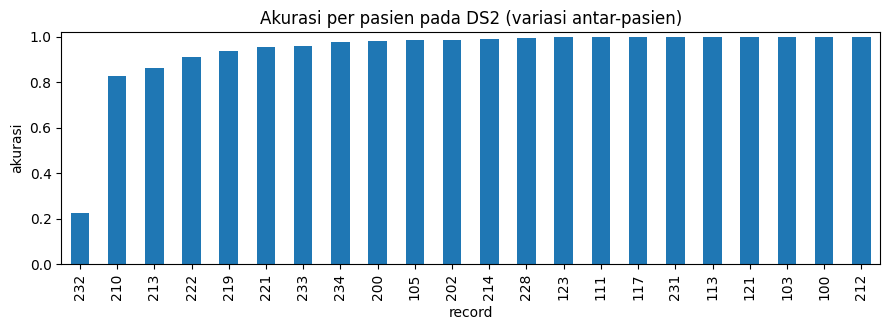


10 fitur dengan pergeseran terbesar (|SMD|; >0,2 ~ kecil, >0,5 ~ sedang):
   fitur    smd  abs_smd
   qrs_w -0.382    0.382
   w_ptp -0.306    0.306
    wv10  0.280    0.280
   w_std -0.243    0.243
area_abs -0.192    0.192
w_energy -0.175    0.175
    wv19  0.172    0.172
    wv18  0.163    0.163
  w_skew  0.158    0.158
    wv03 -0.145    0.145


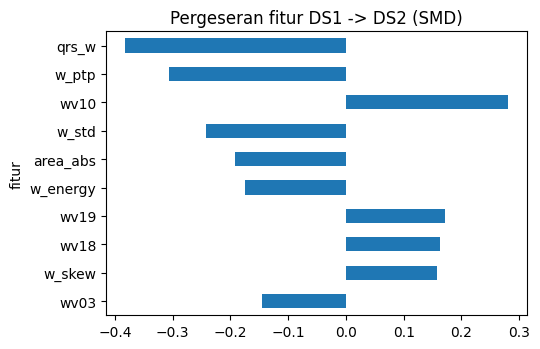

In [16]:
pr = []
for rec, g in pred_test.groupby("record"):
    m = metrics_from(g["y"], g["prediction"])
    pr.append({"record": rec, "n_beat": len(g), "accuracy": m["acc"],
               "recall_S": m["rec"][1], "recall_V": m["rec"][2], "recall_F": m["rec"][3],
               "dirujuk_tau0.7": float((g["maxp"] < 0.7).mean())})
per_rec = pd.DataFrame(pr).sort_values("accuracy")
print(per_rec.round(3).to_string(index=False)); save_table(per_rec, "06_kinerja_per_pasien.csv")

ax = per_rec.set_index("record")["accuracy"].plot(kind="bar", figsize=(9, 3.4))
ax.set_ylim(0, 1.02); ax.set_ylabel("akurasi"); ax.set_title("Akurasi per pasien pada DS2 (variasi antar-pasien)")
savefig("06_akurasi_per_pasien.png")

# drift: standardized mean difference (DS2 - DS1) per fitur
aggs = [F.mean(c).alias(f"m_{c}") for c in FEATS] + [F.stddev(c).alias(f"s_{c}") for c in FEATS]
st = feat.groupBy("split").agg(*aggs).toPandas().set_index("split")
drift = pd.DataFrame({"fitur": FEATS,
                      "smd": [(st.loc["DS2", f"m_{c}"] - st.loc["DS1", f"m_{c}"]) /
                              np.sqrt((st.loc["DS1", f"s_{c}"] ** 2 + st.loc["DS2", f"s_{c}"] ** 2) / 2 + 1e-12) for c in FEATS]})
drift["abs_smd"] = drift["smd"].abs(); drift = drift.sort_values("abs_smd", ascending=False)
print("\n10 fitur dengan pergeseran terbesar (|SMD|; >0,2 ~ kecil, >0,5 ~ sedang):")
print(drift.head(10).round(3).to_string(index=False)); save_table(drift, "06_drift_fitur.csv")
ax = drift.head(10).set_index("fitur")["smd"].plot(kind="barh", figsize=(5.5, 3.6)); ax.invert_yaxis()
ax.set_title("Pergeseran fitur DS1 -> DS2 (SMD)"); savefig("06_drift_fitur.png")

## §7. Komponen 5 — Adaptive governance (bagian 2: skalabilitas)
Artikel mencatat bahwa skalabilitas dan biaya infrastruktur menahan adopsi (§3.4.2). Di mode lokal, "skalabilitas" diukur sebagai **waktu ETL (baca CSV → ekstraksi fitur) dan latih RF** pada `local[1]`, `local[2]`, `local[4]`. Sesi Spark dihentikan dan dibuat ulang untuk tiap konfigurasi, lalu sesi utama dipulihkan. Hasil bergantung pada jumlah core mesin Kaggle; jangan membandingkannya sebagai angka absolut dengan mesin lain.

 cores  beats  etl_s  rf_fit_s  speedup_etl  speedup_rf
     1 100630 129.67    149.14         1.00        1.00
     2 100630  81.93     87.62         1.58        1.70
     4 100630  78.11     78.71         1.66        1.89


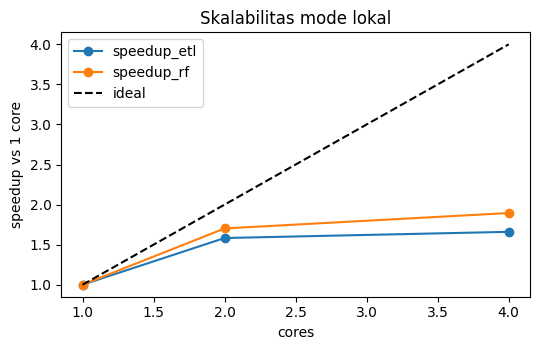

In [17]:
RUN_SCALABILITY = True
CORES_LIST = (1, 2, 4)

def bench_once(cores):
    sp = build_spark(cores=cores, app=f"bench-local{cores}")
    t0 = time.perf_counter()
    s, a = load_sources(sp)
    fb = build_features(s, a).cache(); n = fb.count()
    t_etl = time.perf_counter() - t0
    tr = fb.where(F.col("split") == "DS1"); tr = add_weights(tr, class_weights(tr)).cache(); tr.count()
    t1 = time.perf_counter()
    build_pipeline("RF", FEATS, nt=BEST["nt"], md=BEST["md"]).fit(tr)
    t_fit = time.perf_counter() - t1
    sp.stop()
    return {"cores": cores, "beats": n, "etl_s": t_etl, "rf_fit_s": t_fit}

if RUN_SCALABILITY:
    spark.stop()
    scal = pd.DataFrame([bench_once(k) for k in CORES_LIST])
    scal["speedup_etl"] = scal.etl_s.iloc[0] / scal.etl_s
    scal["speedup_rf"] = scal.rf_fit_s.iloc[0] / scal.rf_fit_s
    print(scal.round(2).to_string(index=False)); save_table(scal, "07_skalabilitas_core.csv")
    ax = scal.set_index("cores")[["speedup_etl", "speedup_rf"]].plot(marker="o", figsize=(5.5, 3.6))
    ax.plot(scal.cores, scal.cores / scal.cores.iloc[0], "k--", label="ideal"); ax.legend()
    ax.set_ylabel("speedup vs 1 core"); ax.set_title("Skalabilitas mode lokal"); savefig("07_skalabilitas_core.png")
    spark = build_spark()                        # pulihkan sesi utama
else:
    print("Uji skalabilitas dilewati (RUN_SCALABILITY=False).")

## §8. Ringkasan, provenance, dan cara mengisi laporan

In [18]:
provenance = {"env": ENV, "seed": SEED, "data_dir": DATA_DIR, "window": {"pre": PRE, "post": POST, "fs": FS},
              "ds1": DS1, "ds2": DS2, "excluded_paced": sorted(PACED), "classes": CLASSES,
              "features": {"rhythm": RHY, "morphology": MOR}, "best_rf": BEST,
              "runlog": RUNLOG, "finished_at_utc": datetime.utcnow().isoformat() + "Z"}
with open(os.path.join(RES_DIR, "run_provenance.json"), "w") as fh:
    json.dump(provenance, fh, indent=2, default=str)

best_row = cmp_df.iloc[0]
print("Model terbaik (macro-F1, DS2):", best_row["model"], round(best_row["macro_f1"], 4))
print("Fusi vs ritme-saja vs morfologi-saja (macro-F1):", abl.set_index("model")["macro_f1"].round(4).to_dict())
print("Intra - antar-pasien (macro-F1):", round(m_intra["macro_f1"] - m_inter["macro_f1"], 4))
print("\nBerkas luaran:"); [print(" ", f) for f in sorted(os.listdir(RES_DIR))]
print("\nRunlog:"); print(pd.DataFrame(RUNLOG).to_string(index=False))

Model terbaik (macro-F1, DS2): Regresi Logistik (berbobot) 0.5251
Fusi vs ritme-saja vs morfologi-saja (macro-F1): {'Ritme saja (6)': 0.4429, 'Morfologi saja (28)': 0.4639, 'Fusi ritme+morfologi (34)': 0.5134}
Intra - antar-pasien (macro-F1): 0.3549

Berkas luaran:
  01_profil_sinyal.csv
  01_simbol_anotasi.csv
  02_distribusi_kelas.csv
  02_distribusi_kelas.png
  03a_cv_antar_pasien.csv
  03b_ablasi_fitur.csv
  03b_ablasi_fitur.png
  03c_confusion_matrix.png
  03c_perbandingan_model.csv
  03d_intra_vs_antar_pasien.csv
  04_streaming_microbatch.csv
  05_triase_confidence.csv
  05_triase_confidence.png
  06_akurasi_per_pasien.png
  06_drift_fitur.csv
  06_drift_fitur.png
  06_kinerja_per_pasien.csv
  07_skalabilitas_core.csv
  07_skalabilitas_core.png
  run_provenance.json

Runlog:
                                            stage  seconds
                          1. akuisisi + profiling    56.49
      2. ekstraksi fitur terdistribusi -> Parquet    83.52
3a. CV antar-pasien (RF, 4 komb

### Panduan mengisi laporan dari keluaran notebook
| Bagian laporan | Ambil dari |
|---|---|
| B. Lingkungan & versi | `run_provenance.json`, sel §0 |
| B. Praproses & rancangan | §1–§2, `02_distribusi_kelas.csv` |
| C. Tabel ablasi / model / intra-antar | `03b`, `03c`, `03d` |
| C. Real-time | `04_streaming_microbatch.csv` |
| C. Validasi manusia | `05_triase_confidence.csv` |
| C. Tata kelola | `06_*` dan `07_skalabilitas_core.csv` |
| C. Perbandingan dengan artikel | tabel klaim artikel ↔ bukti (lihat kerangka laporan) |

### Keterbatasan yang perlu dinyatakan jujur di laporan
- Artikel acuan tidak memiliki angka hasil; perbandingan hanya kualitatif.
- Domain berbeda (EKG vs teks), sehingga "sentimen" tidak direplikasi; yang dioperasionalkan adalah *logika kerangka* (sinyal tambahan, fusi, validasi manusia, tata kelola).
- Hanya 44 rekaman (22 pasien uji), kelas S dan F sangat sedikit; hasil per-kelas bervariasi besar.
- Spark berjalan mode lokal pada satu mesin: tidak menguji klaster terdistribusi sungguhan.
- NoSQL tidak dipakai; penyimpanan yang dipakai adalah Parquet.